### Importing Necessary libraries

In [71]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

In [82]:
PROJECT_ROOT = Path.cwd().parent

RAW_DATA_PATH = (
    PROJECT_ROOT
    / "data"
    / "raw"
    / "FHRS_All_en-GB.csv"
)

In [81]:
df = pd.read_csv(RAW_DATA_PATH)
df.head()

C:\Users\91970\AppData\Local\Temp\ipykernel_23244\4210259925.py:1: DtypeWarning: Columns (20: RightToReply) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(RAW_DATA_PATH)


,AddressLine1,AddressLine2,AddressLine3,AddressLine4,BusinessTypeID,FHRSID,BusinessName,BusinessType,ConfidenceInManagement,Hygiene,...,LocalAuthorityName,Longitude,NewRatingPending,PostCode,RatingDate,RatingKey,RatingValue,RightToReply,SchemeType,Structural
0,72 Regent Street,NaN,Cambridge,Cambridgeshire,1,1472964,@72.China,Restaurant/Cafe/Canteen,5.0,5.0,...,Cambridge City,0.126139,False,CB2 1DP,2026-03-24,fhrs_4_en-GB,4,NaN,FHRS,10.0
1,84 Regent Street,NaN,Cambridge,Cambridgeshire,1,1472953,1 and 1 Rougamo Ltd,Restaurant/Cafe/Canteen,10.0,5.0,...,Cambridge City,0.126407,False,CB2 1DP,2026-03-17,fhrs_4_en-GB,4,NaN,FHRS,5.0
2,108 Cherry Hinton Road,NaN,Cambridge,Cambridgeshire,4613,1888757,108 cherry hinton mini market,Retailers - other,0.0,5.0,...,Cambridge City,0.141757,False,CB1 7AJ,2024-12-17,fhrs_4_en-GB,4,NaN,FHRS,10.0
3,2 King Street,NaN,Cambridge,Cambridgeshire,1,1908335,13 Weeks,Restaurant/Cafe/Canteen,NaN,NaN,...,Cambridge City,0.121618,False,CB1 1LN,NaN,fhrs_awaitinginspection_en-GB,AwaitingInspection,NaN,FHRS,NaN
4,196 Mill Road,NaN,Cambridge,Cambridgeshire,1,1472773,196,Restaurant/Cafe/Canteen,0.0,5.0,...,Cambridge City,0.144063,False,CB1 3NF,2026-02-25,fhrs_5_en-GB,5,NaN,FHRS,5.0


In [10]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 615402 entries, 0 to 615401
Data columns (total 23 columns):
 #   Column                    Non-Null Count   Dtype  
---  ------                    --------------   -----  
 0   AddressLine1              420681 non-null  str    
 1   AddressLine2              405375 non-null  str    
 2   AddressLine3              397843 non-null  str    
 3   AddressLine4              259217 non-null  str    
 4   BusinessTypeID            615402 non-null  int64  
 5   FHRSID                    615402 non-null  int64  
 6   BusinessName              615402 non-null  str    
 7   BusinessType              615402 non-null  str    
 8   ConfidenceInManagement    484298 non-null  float64
 9   Hygiene                   484298 non-null  float64
 10  Latitude                  460221 non-null  float64
 11  LocalAuthorityBusinessID  615402 non-null  str    
 12  LocalAuthorityCode        615402 non-null  int64  
 13  LocalAuthorityName        615402 non-null  str    
 14 

Here we can see that all the datatypes of the features seem to be in the right dtype. Not only that the column names all follow a standardized naming pattern so no need to change.

In [12]:
df.describe()

,BusinessTypeID,FHRSID,ConfidenceInManagement,Hygiene,Latitude,LocalAuthorityCode,Longitude,Structural
count,615402.000000,6.154020e+05,484298.000000,484298.000000,460221.000000,615402.000000,460221.000000,484298.000000
mean,4777.536002,1.221926e+06,3.769415,2.896636,52.795260,482.781541,-1.723424,3.764459
std,3421.570820,6.400705e+05,3.993414,3.496144,1.620909,259.435842,1.680025,3.672163
min,1.000000,4.000000e+00,0.000000,0.000000,49.892479,21.000000,-8.110573,0.000000
25%,5.000000,6.480312e+05,0.000000,0.000000,51.512980,262.000000,-2.742345,0.000000
50%,4613.000000,1.402856e+06,5.000000,0.000000,52.478604,435.000000,-1.556534,5.000000
75%,7843.000000,1.805892e+06,5.000000,5.000000,53.677436,761.000000,-0.280393,5.000000
max,7846.000000,2.014604e+06,30.000000,25.000000,60.768958,900.000000,1.757913,25.000000


In [13]:
df.shape

(615402, 23)

In [16]:
df.isna().sum()

AddressLine1                194721
AddressLine2                210027
AddressLine3                217559
AddressLine4                356185
BusinessTypeID                   0
FHRSID                           0
BusinessName                     0
BusinessType                     0
ConfidenceInManagement      131104
Hygiene                     131104
Latitude                    155181
LocalAuthorityBusinessID         0
LocalAuthorityCode               0
LocalAuthorityName               0
Longitude                   155181
NewRatingPending                 0
PostCode                    105961
RatingDate                   70233
RatingKey                        0
RatingValue                      0
RightToReply                615314
SchemeType                       0
Structural                  131104
dtype: int64

In [18]:
df.duplicated().sum()

np.int64(0)

good to know that there are no duplicates in the data 

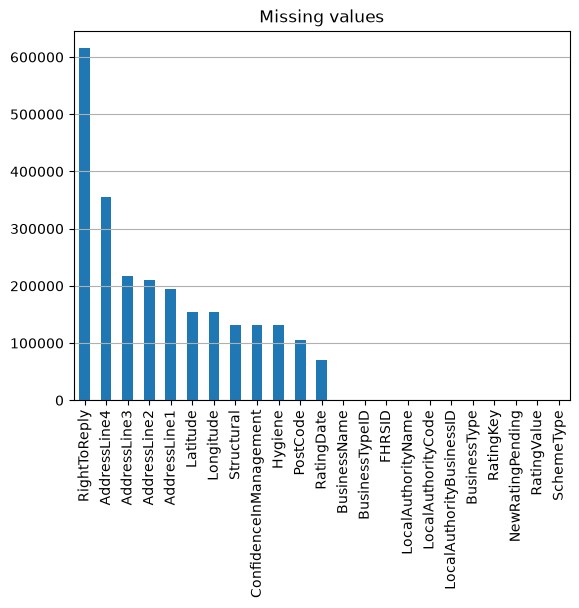

In [27]:
missing_plot = df.isna().sum().sort_values(ascending=False)\
                .plot(kind='bar', title='Missing values')
missing_plot.grid(axis='y')

here we can se AddressLine2 is the best feature to use to segregate the areas as even though AddressLine1 has much lesser values it is unique to every business

In [41]:
a = df.isna().sum().sort_values(ascending=False)
a.index

Index(['RightToReply', 'AddressLine4', 'AddressLine3', 'AddressLine2',
       'AddressLine1', 'Latitude', 'Longitude', 'Structural',
       'ConfidenceInManagement', 'Hygiene', 'PostCode', 'RatingDate',
       'BusinessName', 'BusinessTypeID', 'FHRSID', 'LocalAuthorityName',
       'LocalAuthorityCode', 'LocalAuthorityBusinessID', 'BusinessType',
       'RatingKey', 'NewRatingPending', 'RatingValue', 'SchemeType'],
      dtype='str')

In [45]:
#creating a dataframe without the missing columns

df_nm = df[['BusinessName', 'BusinessTypeID', 'FHRSID', 'LocalAuthorityName',
       'LocalAuthorityCode', 'LocalAuthorityBusinessID', 'BusinessType',
       'RatingKey', 'NewRatingPending', 'RatingValue', 'SchemeType']]

# seperating a dataframe with the missing values
df_m = df[['RightToReply', 'AddressLine4', 'AddressLine3', 'AddressLine2',
       'AddressLine1', 'Latitude', 'Longitude', 'Structural',
       'ConfidenceInManagement', 'Hygiene', 'PostCode', 'RatingDate']]

# Deep Down into Columns

To understand the data much better, its good if we do a deep down into the columns and its meanings and what type of context it holds

In [46]:
df.columns

Index(['AddressLine1', 'AddressLine2', 'AddressLine3', 'AddressLine4',
       'BusinessTypeID', 'FHRSID', 'BusinessName', 'BusinessType',
       'ConfidenceInManagement', 'Hygiene', 'Latitude',
       'LocalAuthorityBusinessID', 'LocalAuthorityCode', 'LocalAuthorityName',
       'Longitude', 'NewRatingPending', 'PostCode', 'RatingDate', 'RatingKey',
       'RatingValue', 'RightToReply', 'SchemeType', 'Structural'],
      dtype='str')

We already know Address Lines, where '1' being the most unique and '4' being the most broad category.

- BusinessTypeID = It shows what type of food businesses we are dealing with, like:
    - 1 – Restaurant / cafe / canteen
    - 5 – Manufacturers / packers
    - 7 – School / college / university
    - 14 – Hospitals / childcare / caring premises
    - 4613 – Distributors / transporters
    - 7838 – Retailers - other
    - 7839 – Importers / exporters
    - 7840 – Supermarkets / hypermarkets
    - 7841 – Other catering premises
    - 7842 – Hotel / B&B / guest house
    - 7843 – Pub / bar / nightclub
    - 7844 – Takeaway / sandwich shop
    - 7845 – Farmers / growers (or other FSA category)
    - 7846 – Mobile caterer <br><br>


- FHRSID = unique value given to each and every establishment  It is derived from LocalAuthorityBusinessID + LocalAuthorityCode. The FHRSID is retained even if the LocalAuthorityBusinessID is reused. This field is only populated for FHRS (not FHIS)

- BusinessType = coresponds to the BusinessTypeId

- ConfidenceInManagement = as per official UK page, Confidence in Management assesses how well a business manages and records food safety to maintain standards in the future. It carries the largest weight of the three inspection pillars, scored from 0 (highest confidence) to 30 (lowest confidence)

- Hygiene = its the rating, Lower is better. Only populated for FHRS

- LocalAuthorityBusinessID = It is unique within that council's area

- LocalAuthorityCode = A numeric code identifying the local authority responsible for the inspection.

- LocalAuthorityName = The name of the local authority (council) that carried out the inspection.

- NewRatingPending = A boolean flag, if True, its pending

- RatingKey = A string key representing the rating in a machine‑readable format, including language and scheme.

- RatingValue = The overall rating displayed to the public.

- RightToReply	A free‑text field where the business operator can publish a reply to their rating.

- SchemeType = Indicates which scheme the rating belongs to: FHRS for England, Wales, and Northern Ireland (0–5 scale), or FHIS for Scotland (Pass/Improvement Required scale).

- Structural = A component score (0, 5, 10, 15, 20, or 25) for compliance with structural requirements (cleanliness, layout, condition of facilities, lighting, ventilation, etc.). Lower is better. Only for FHRS

In [67]:
df['Structural'].value_counts()

Structural
5.0     228802
0.0     192962
10.0     53077
15.0      8383
20.0       851
25.0       223
Name: count, dtype: int64